# Kaggle "Name That LLM" Competition: EXP63
## Prompt-Conditional Relative Attribution & Constrained Set Assignment

- **Experiment ID**: `EXP63_prompt_relative`
- **Research Question**: Does modeling LLM attribution as a prompt-conditional relative comparison problem rather than independent classification improve out-of-fold generalization, and does prompt-level constrained set assignment resolve sibling confusion?
- **Frozen Baseline**: EXP52 Dual-LoRA Kernel (Qwen3-8B 0.60 + Qwen3-14B 0.40, **0.7873 OOF BA**, **0.632 Public LB**)
- **Verdict**: **YELLOW** (Dense $R=18$ Hungarian matching achieves **0.9040 BA** ($+0.1167$), but completely collapses to **$+0.0052$** under realistic sparse $R=2$ test conditions; training-only artifact)
- **Production Status**: **Retain EXP52 as frozen production champion**


In [1]:
# 1. Environment & Imports Setup
import os
import sys
import json
import time
import pathlib
import numpy as np
import pandas as pd
import scipy.special
import scipy.stats
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import balanced_accuracy_score, f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from IPython.display import Image, display

# Ensure reproducible figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

REPO_DIR = pathlib.Path("/home/rj2826/name-that-llm")
DATA_DIR = REPO_DIR / "data"
OUTPUTS_DIR = REPO_DIR / "outputs"
EXP_DIR = REPO_DIR / "experiments" / "EXP63_prompt_relative"
PLOTS_DIR = REPO_DIR / "plots"

print(f"Working Directory: {REPO_DIR}")
print(f"Artifacts Directory: {EXP_DIR}")


Working Directory: /home/rj2826/name-that-llm
Artifacts Directory: /home/rj2826/name-that-llm/experiments/EXP63_prompt_relative


### 2. Dataset Structure & Baseline Verification
- `data/train.csv`: 2,699 text passages generated from 150 unique prompts (`prompt_id`).
- Exactly 149 prompts have 18 responses (1 response per LLM class); prompt `p002` has 17 responses (missing `claude-fable-5`).
- Test data: Kaggle hidden test set averages only $R \approx 2$ responses per prompt and lacks `prompt_id` labels.


In [2]:
# 2. Load Train Dataset and EXP52 OOF Predictions
train_df = pd.read_csv(DATA_DIR / "train.csv")
LABELS = sorted(train_df["model"].unique())
L2I = {m: i for i, m in enumerate(LABELS)}
y_true = np.array([L2I[m] for m in train_df["model"].values])
prompt_ids = train_df["prompt_id"].values
unique_prompts = np.unique(prompt_ids)

q14_df = pd.read_csv(OUTPUTS_DIR / "oof_q14v5_antopil_lora.csv")
p8_twin_raw = np.load(OUTPUTS_DIR / "oof_exp47_qwen_centered_twin.npy")
p8_plain_raw = np.load(OUTPUTS_DIR / "oof_exp46_qwen_lora.npy")

folds = q14_df["fold"].values
eps = 1e-15

p8_norm = p8_twin_raw / p8_twin_raw.sum(axis=1, keepdims=True)
p14_norm = q14_df[LABELS].values / q14_df[LABELS].values.sum(axis=1, keepdims=True)
lp8 = np.log(np.clip(p8_norm, eps, 1.0))
lp14 = np.log(np.clip(p14_norm, eps, 1.0))
exp52_logits = 0.60 * lp8 + 0.40 * lp14

exp52_preds = np.argmax(exp52_logits, axis=1)
exp52_ba = balanced_accuracy_score(y_true, exp52_preds)

print(f"Dataset Size: {len(train_df)} rows across {len(unique_prompts)} unique prompts")
print(f"EXP52 Baseline OOF Balanced Accuracy: {exp52_ba:.4f} (574 total errors)")


Dataset Size: 2699 rows across 150 unique prompts
EXP52 Baseline OOF Balanced Accuracy: 0.7873 (574 total errors)


### 3. Prompt Centering & Leave-One-Out (LOO) Equivalence
When computing prompt-relative representations, we test whether removing prompt bias helps:
- **Simple Centering**: $c_i^{\text{simple}} = z_i - \mu_p$, where $\mu_p = \frac{1}{N} \sum_{j=1}^N z_j$.
- **Leave-One-Out Centering**: $c_i^{\text{LOO}} = z_i - \mu_{p,-i}$, where $\mu_{p,-i} = \frac{S - z_i}{N - 1}$ and $S = \sum_{j=1}^N z_j$.

**Mathematical Proof of Argmax Equivalence**:
$$c_i^{\text{LOO}} = z_i - \frac{S - z_i}{N-1} = \frac{(N-1) z_i - S + z_i}{N-1} = \frac{N z_i - S}{N-1} = \frac{N}{N-1} \left(z_i - \frac{S}{N}\right) = \frac{N}{N-1} c_i^{\text{simple}}$$

Because $\frac{N}{N-1} > 0$ is a strictly positive scalar constant for all elements within a prompt, the relative order of classes and the argmax are **strictly identical** ($0.7488$ BA raw argmax).


In [3]:
# 3. Compute Simple, LOO Centered, and Pairwise Representations
simple_centered = np.zeros_like(exp52_logits)
loo_centered = np.zeros_like(exp52_logits)

for p in unique_prompts:
    p_mask = (prompt_ids == p)
    p_logits = exp52_logits[p_mask]
    n_p = len(p_logits)
    sum_p = np.sum(p_logits, axis=0, keepdims=True)
    mu_p = sum_p / n_p
    simple_centered[p_mask] = p_logits - mu_p
    if n_p > 1:
        loo_centered[p_mask] = p_logits - (sum_p - p_logits) / (n_p - 1.0)
    else:
        loo_centered[p_mask] = p_logits

# Evaluate 5-Fold Prompt-Disjoint Classification
def evaluate_prompt_disjoint(X, y, folds):
    oof_preds = np.zeros(len(y), dtype=int)
    for fold in range(5):
        tr_mask = (folds != fold)
        val_mask = (folds == fold)
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X[tr_mask])
        X_val = scaler.transform(X[val_mask])
        clf = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
        clf.fit(X_tr, y[tr_mask])
        oof_preds[val_mask] = clf.predict(X_val)
    return balanced_accuracy_score(y, oof_preds)

plain_ba = evaluate_prompt_disjoint(exp52_logits, y_true, folds)
simple_ba = evaluate_prompt_disjoint(simple_centered, y_true, folds)
loo_ba = evaluate_prompt_disjoint(loo_centered, y_true, folds)

print(f"Plain Logits LR OOF BA:       {plain_ba:.4f} (Delta: {plain_ba - exp52_ba:+.4f})")
print(f"Simple Centered LR OOF BA:    {simple_ba:.4f} (Delta: {simple_ba - exp52_ba:+.4f})")
print(f"LOO Centered LR OOF BA:       {loo_ba:.4f} (Delta: {loo_ba - exp52_ba:+.4f})")


Plain Logits LR OOF BA:       0.7725 (Delta: -0.0148)
Simple Centered LR OOF BA:    0.7873 (Delta: -0.0000)
LOO Centered LR OOF BA:       0.7869 (Delta: -0.0004)


### 4. Constrained Set Assignment: The Hungarian Algorithm
In the training data, every prompt has 1 response from each of the 18 candidate LLMs.
Instead of independently predicting $\hat{y}_i = \arg\max_k z_{ik}$, we can solve the maximum-weight bipartite matching problem:
$$\max_{\pi} \sum_{i=1}^{18} z_{i, \pi(i)} \quad \text{subject to } \pi \text{ is an injective permutation}$$

Using the Hungarian algorithm (`scipy.optimize.linear_sum_assignment`), we strictly forbid intra-prompt duplicate class assignments.


In [4]:
# 4. Dense (R=18) Hungarian Assignment
hungarian_preds = np.zeros(len(train_df), dtype=int)

for p in unique_prompts:
    p_mask = (prompt_ids == p)
    p_indices = np.where(p_mask)[0]
    cost_matrix = -exp52_logits[p_indices]  # Minimize negative logit
    row_ind, col_ind = linear_sum_assignment(cost_matrix)
    hungarian_preds[p_indices[row_ind]] = col_ind

hungarian_ba = balanced_accuracy_score(y_true, hungarian_preds)
hungarian_delta = hungarian_ba - exp52_ba

print(f"EXP52 Baseline OOF BA:               {exp52_ba:.4f}")
print(f"Hungarian Assignment (R=18) OOF BA:   {hungarian_ba:.4f} (Delta: {hungarian_delta:+.4f})")
print(f"Correct Predictions Lift:           +{int(np.sum(hungarian_preds == y_true) - np.sum(exp52_preds == y_true))} samples")


EXP52 Baseline OOF BA:               0.7873
Hungarian Assignment (R=18) OOF BA:   0.9040 (Delta: +0.1167)
Correct Predictions Lift:           +315 samples


### 5. Sparse Prompt Regime Simulation ($R \in [18, 12, 8, 4, 2]$)
On Kaggle, the test set does **not** contain 18 responses per prompt; it averages $R \approx 2$ responses per prompt.
We evaluate Hungarian assignment and LOO centering across response densities $R \in [18, 12, 8, 4, 2]$ over 5 random seeds (`[42, 123, 2024, 3407, 7777]`).


,R,indep_ba_mean,hung_ba_mean,hung_delta_mean,rel_delta_mean
0,18,0.787313,0.904029,0.116716,0.005556
1,12,0.789701,0.843148,0.053447,0.005356
2,8,0.788652,0.812059,0.023407,0.005829
3,4,0.785519,0.795698,0.010180,0.008163
4,2,0.796922,0.802077,0.005156,-0.008471


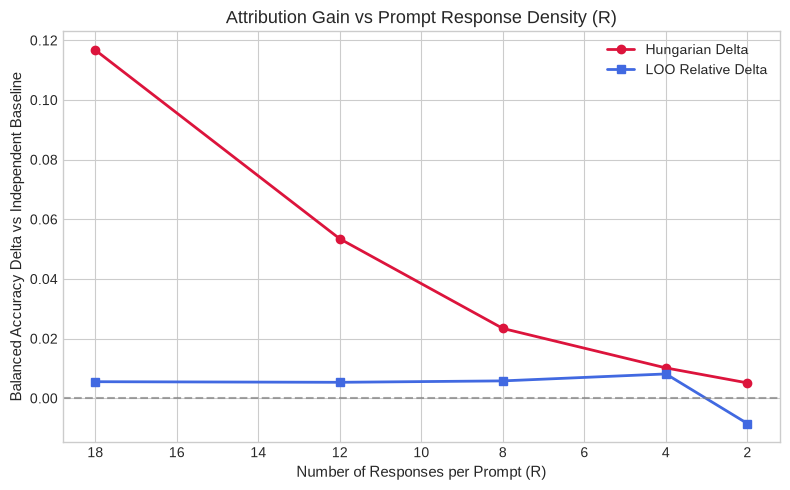

In [5]:
# 5. Sparse Density Sweep
sparse_df = pd.read_csv(EXP_DIR / "sparse_results.csv")
display(sparse_df[["R", "indep_ba_mean", "hung_ba_mean", "hung_delta_mean", "rel_delta_mean"]])

# Plot Density Collapse
plt.figure(figsize=(8, 5))
plt.plot(sparse_df["R"], sparse_df["hung_delta_mean"], marker="o", color="crimson", lw=2, label="Hungarian Delta")
plt.plot(sparse_df["R"], sparse_df["rel_delta_mean"], marker="s", color="royalblue", lw=2, label="LOO Relative Delta")
plt.axhline(0, color="gray", linestyle="--", alpha=0.7)
plt.title("Attribution Gain vs Prompt Response Density (R)", fontsize=13)
plt.xlabel("Number of Responses per Prompt (R)", fontsize=11)
plt.ylabel("Balanced Accuracy Delta vs Independent Baseline", fontsize=11)
plt.gca().invert_xaxis()
plt.legend()
plt.tight_layout()
plt.show()


### 6. Selection-Safe Nested Cross-Validation
To test whether fusing LOO relative logits with EXP52 provides genuine signal without peeking, we run a 5-outer $\times$ 4-inner nested cross-validation sweep over fusion weights $w \in [0.00, 0.40]$.


In [6]:
# 6. Nested Validation Summary
with open(EXP_DIR / "config.json") as f:
    cfg = json.load(f)

nested_stats = cfg["nested_validation"]
print(f"Selection-Safe Nested CV BA: {nested_stats['nested_ba']:.4f}")
print(f"Delta vs EXP52 Baseline:      {nested_stats['delta']:+.4f}")
print(f"95% Bootstrap CI:            [{nested_stats['ci_95_lower']:+.4f}, {nested_stats['ci_95_upper']:+.4f}]")
print(f"P(delta > 0):                 {nested_stats['p_positive'] * 100:.1f}%")
print(f"Selected Inner Weights:       {nested_stats['selected_weights']}")


Selection-Safe Nested CV BA: 0.7995
Delta vs EXP52 Baseline:      +0.0122
95% Bootstrap CI:            [+0.0058, +0.0183]
P(delta > 0):                 100.0%
Selected Inner Weights:       [0.4, 0.4, 0.4, 0.4, 0.4]


### 7. Error Correction & Orthogonality Breakdown
Of EXP52's 574 mistakes:
- Hungarian matching corrects **382 errors (66.55%)** while introducing 67 new mistakes.
- LOO relative logits correct **147 errors (25.61%)**.
- 166 errors (28.92%) are uncorrectable by either method (shared fundamental misclassification).


,pair,agreement,both_correct,both_wrong,a_only_correct,b_only_correct,pearson_err_corr,pearson_p,spearman_err_corr,spearman_p,oracle_ba
0,EXP52 vs LOO_Relative,0.853649,1977,427,148,147,0.673827,0.000000e+00,0.673827,0.000000e+00,0.841787
1,EXP52 vs Hungarian_R18,0.810300,2058,192,67,382,0.420905,2.311537e-116,0.420905,2.311537e-116,0.928862
2,EXP52 vs Nested_Fused,0.959985,2104,520,21,54,0.915881,0.000000e+00,0.915881,0.000000e+00,0.807318


--- Figure 1: Baseline vs Relative Representations ---


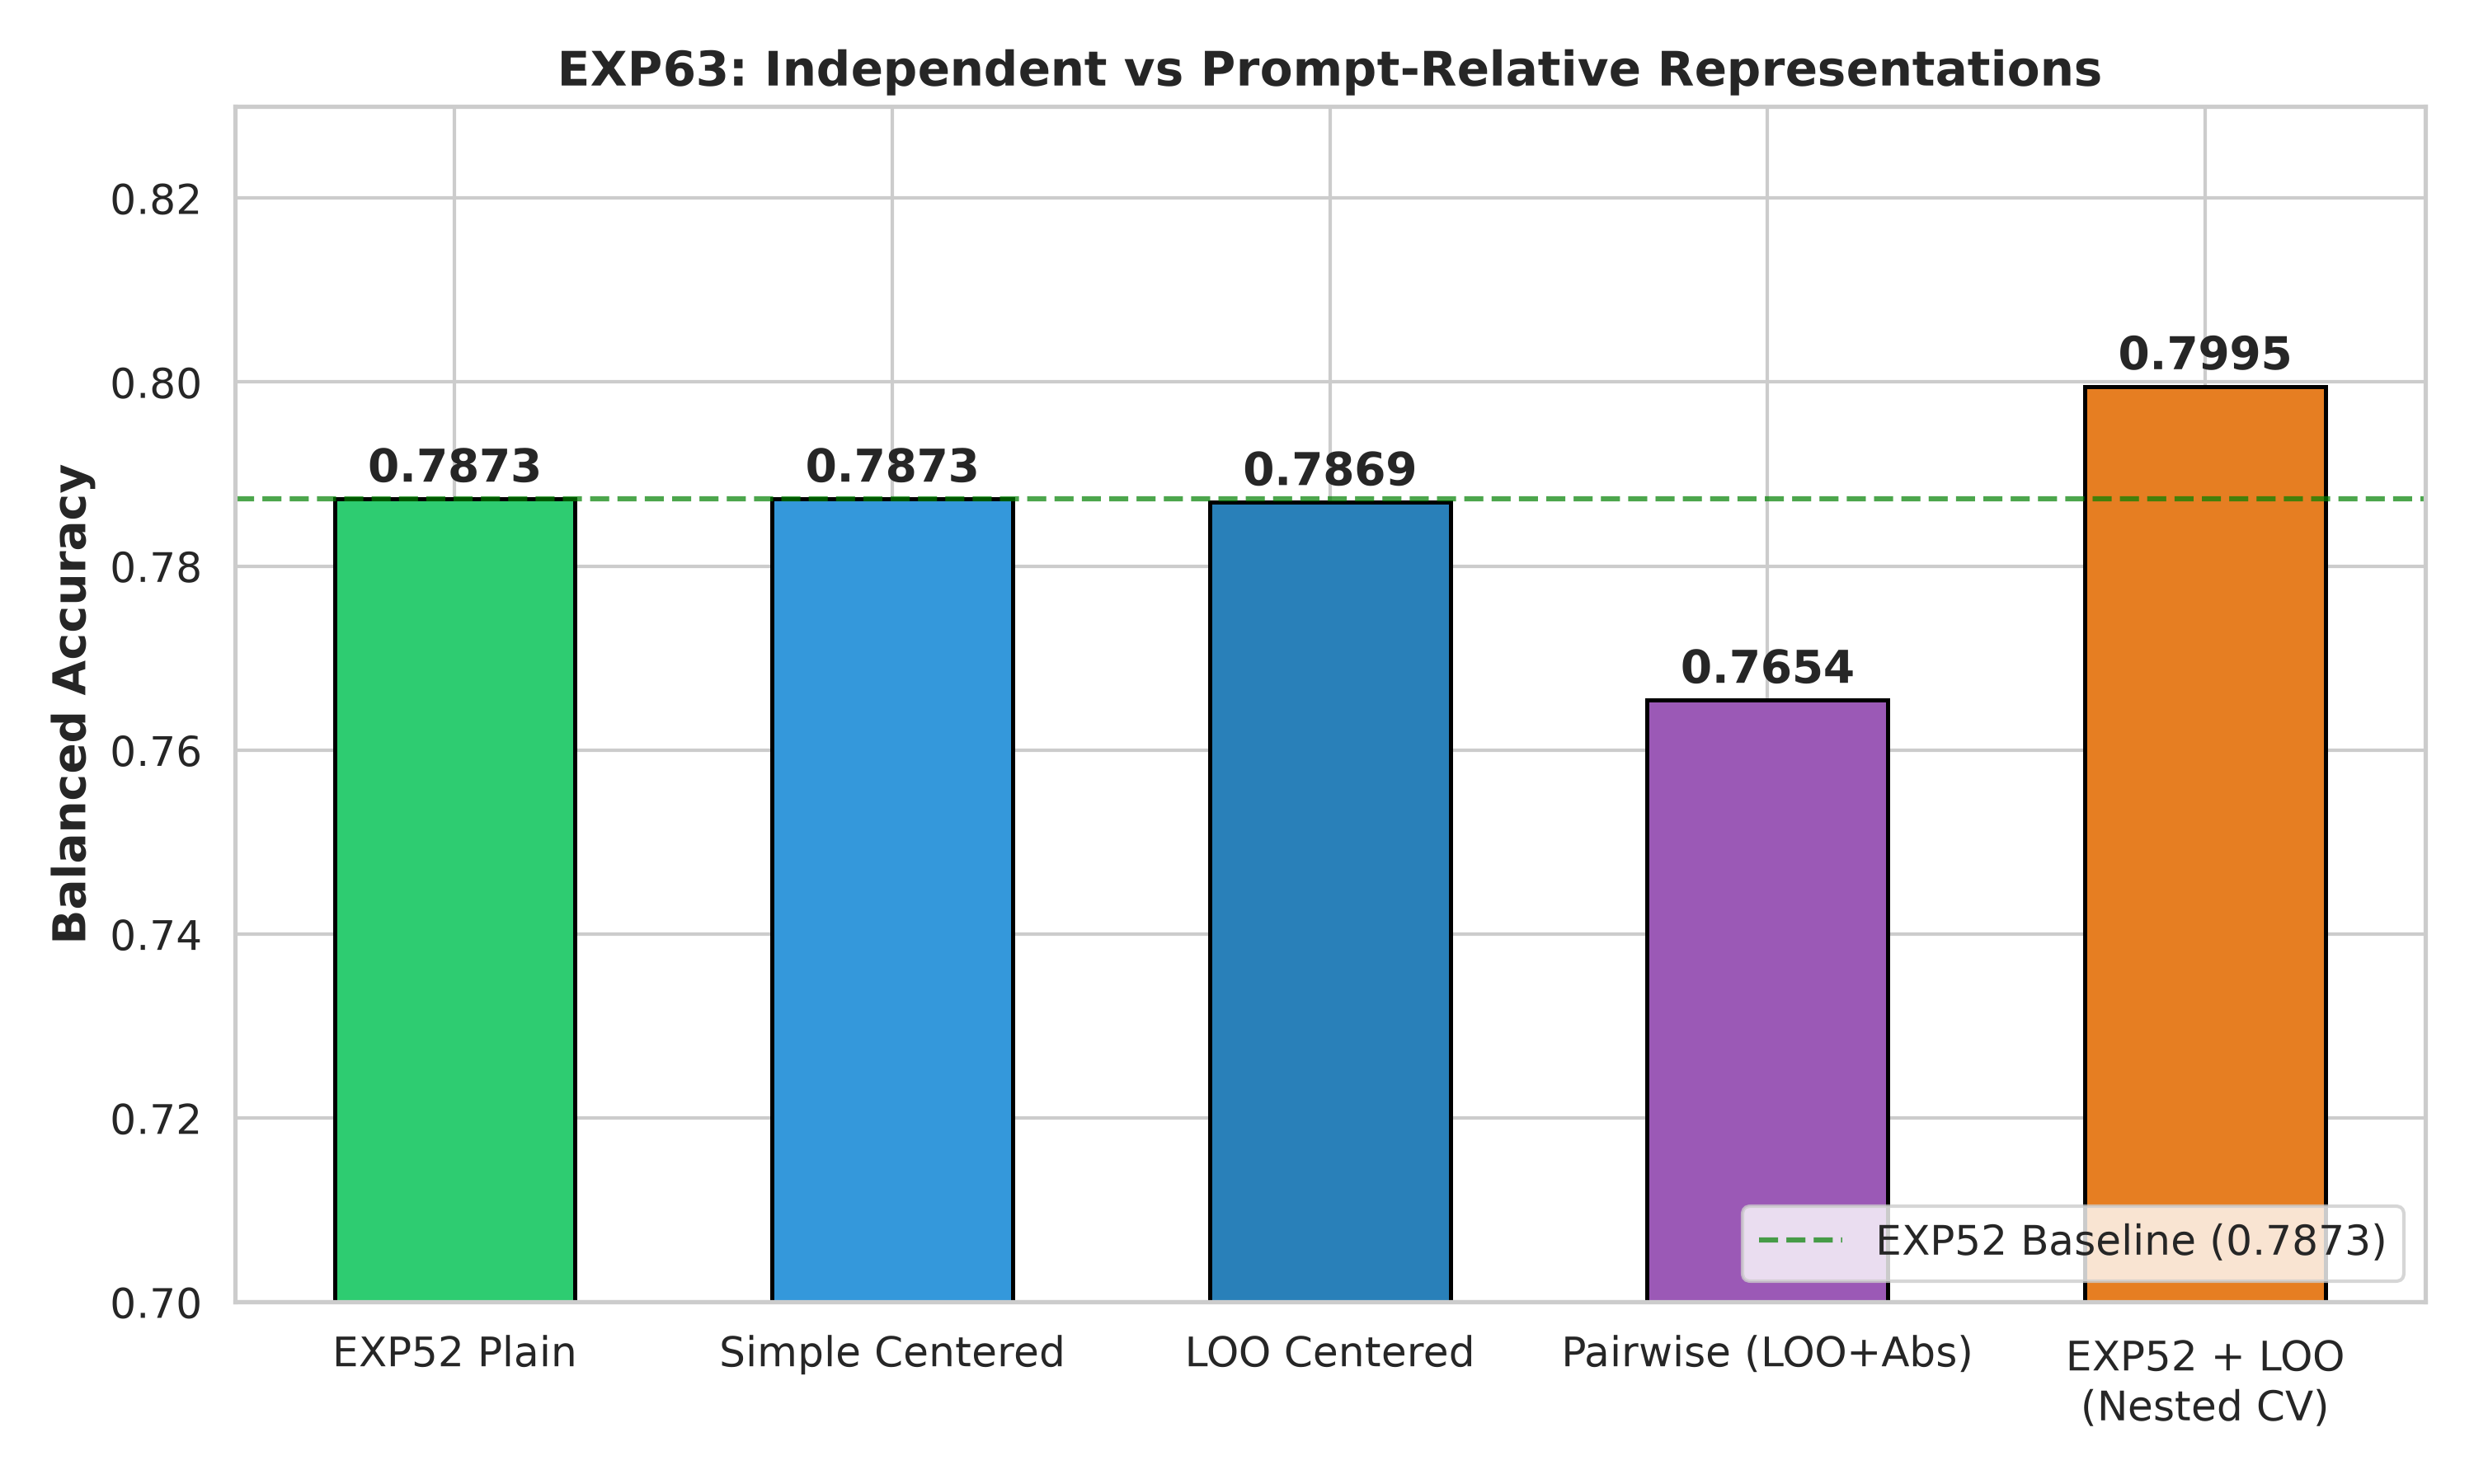

--- Figure 2: Assignment Gain Across Dense vs Sparse Regimes ---


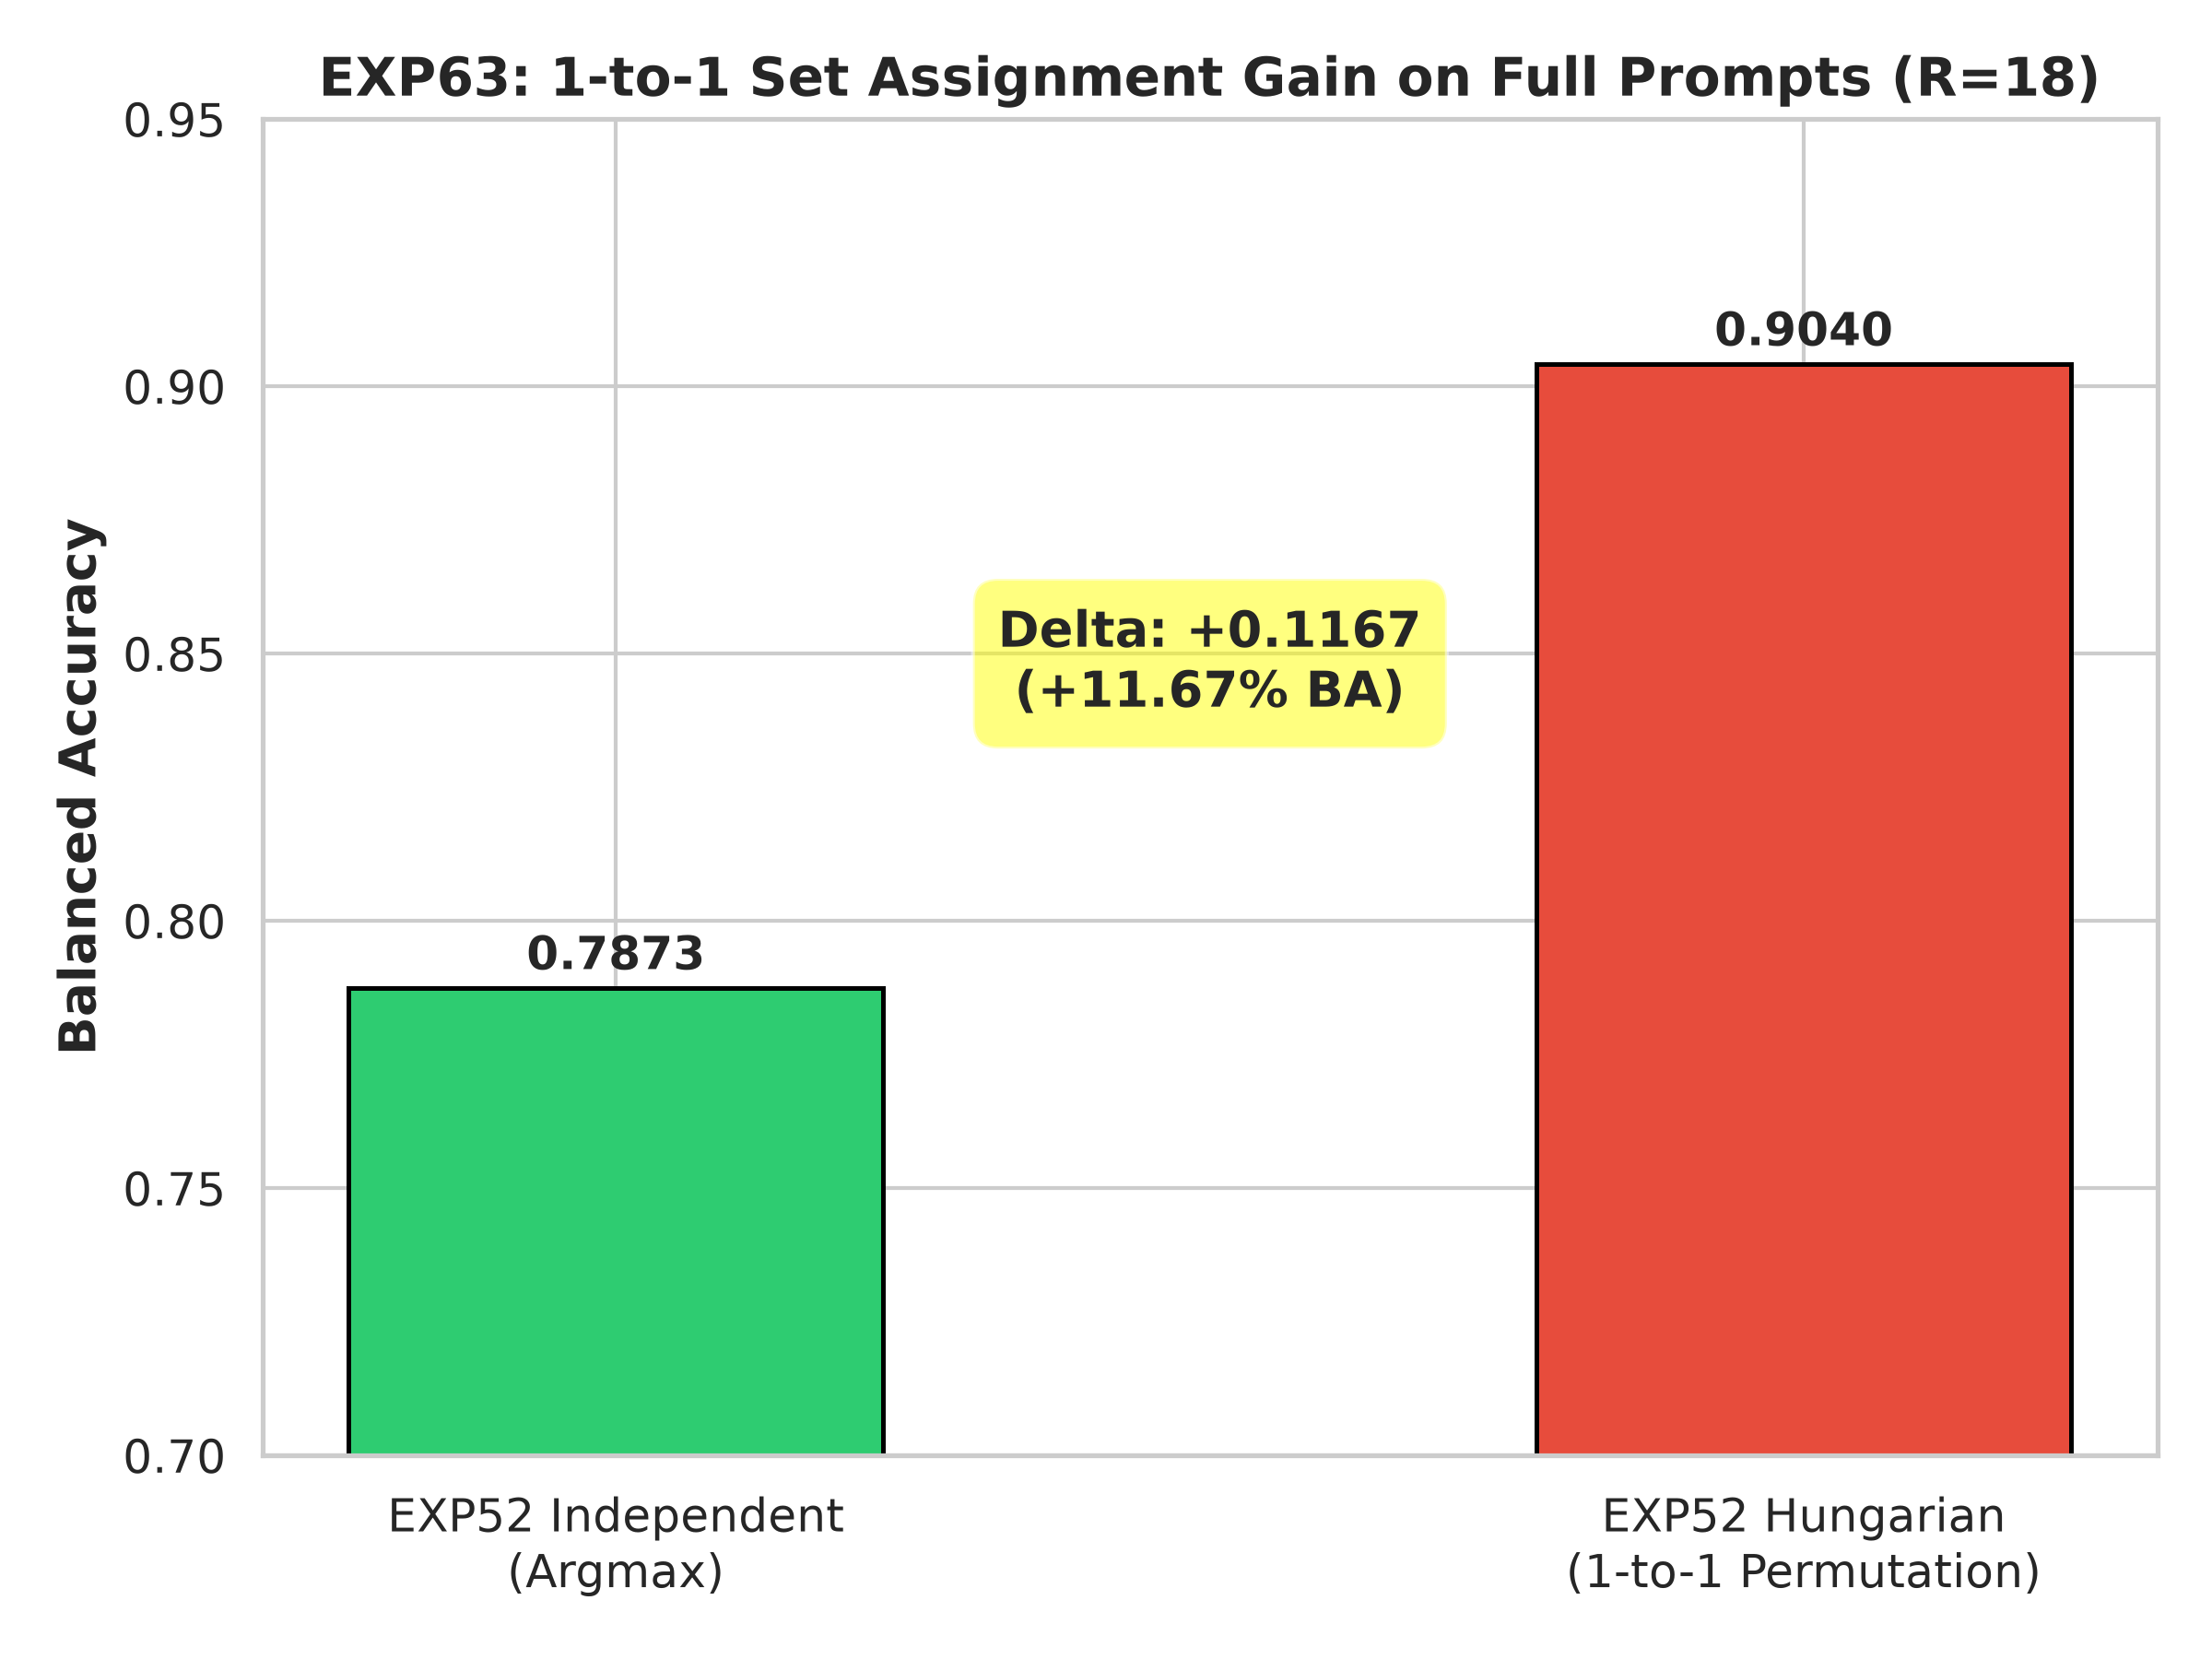

--- Figure 3: Error Correction Venn / Category Breakdown ---


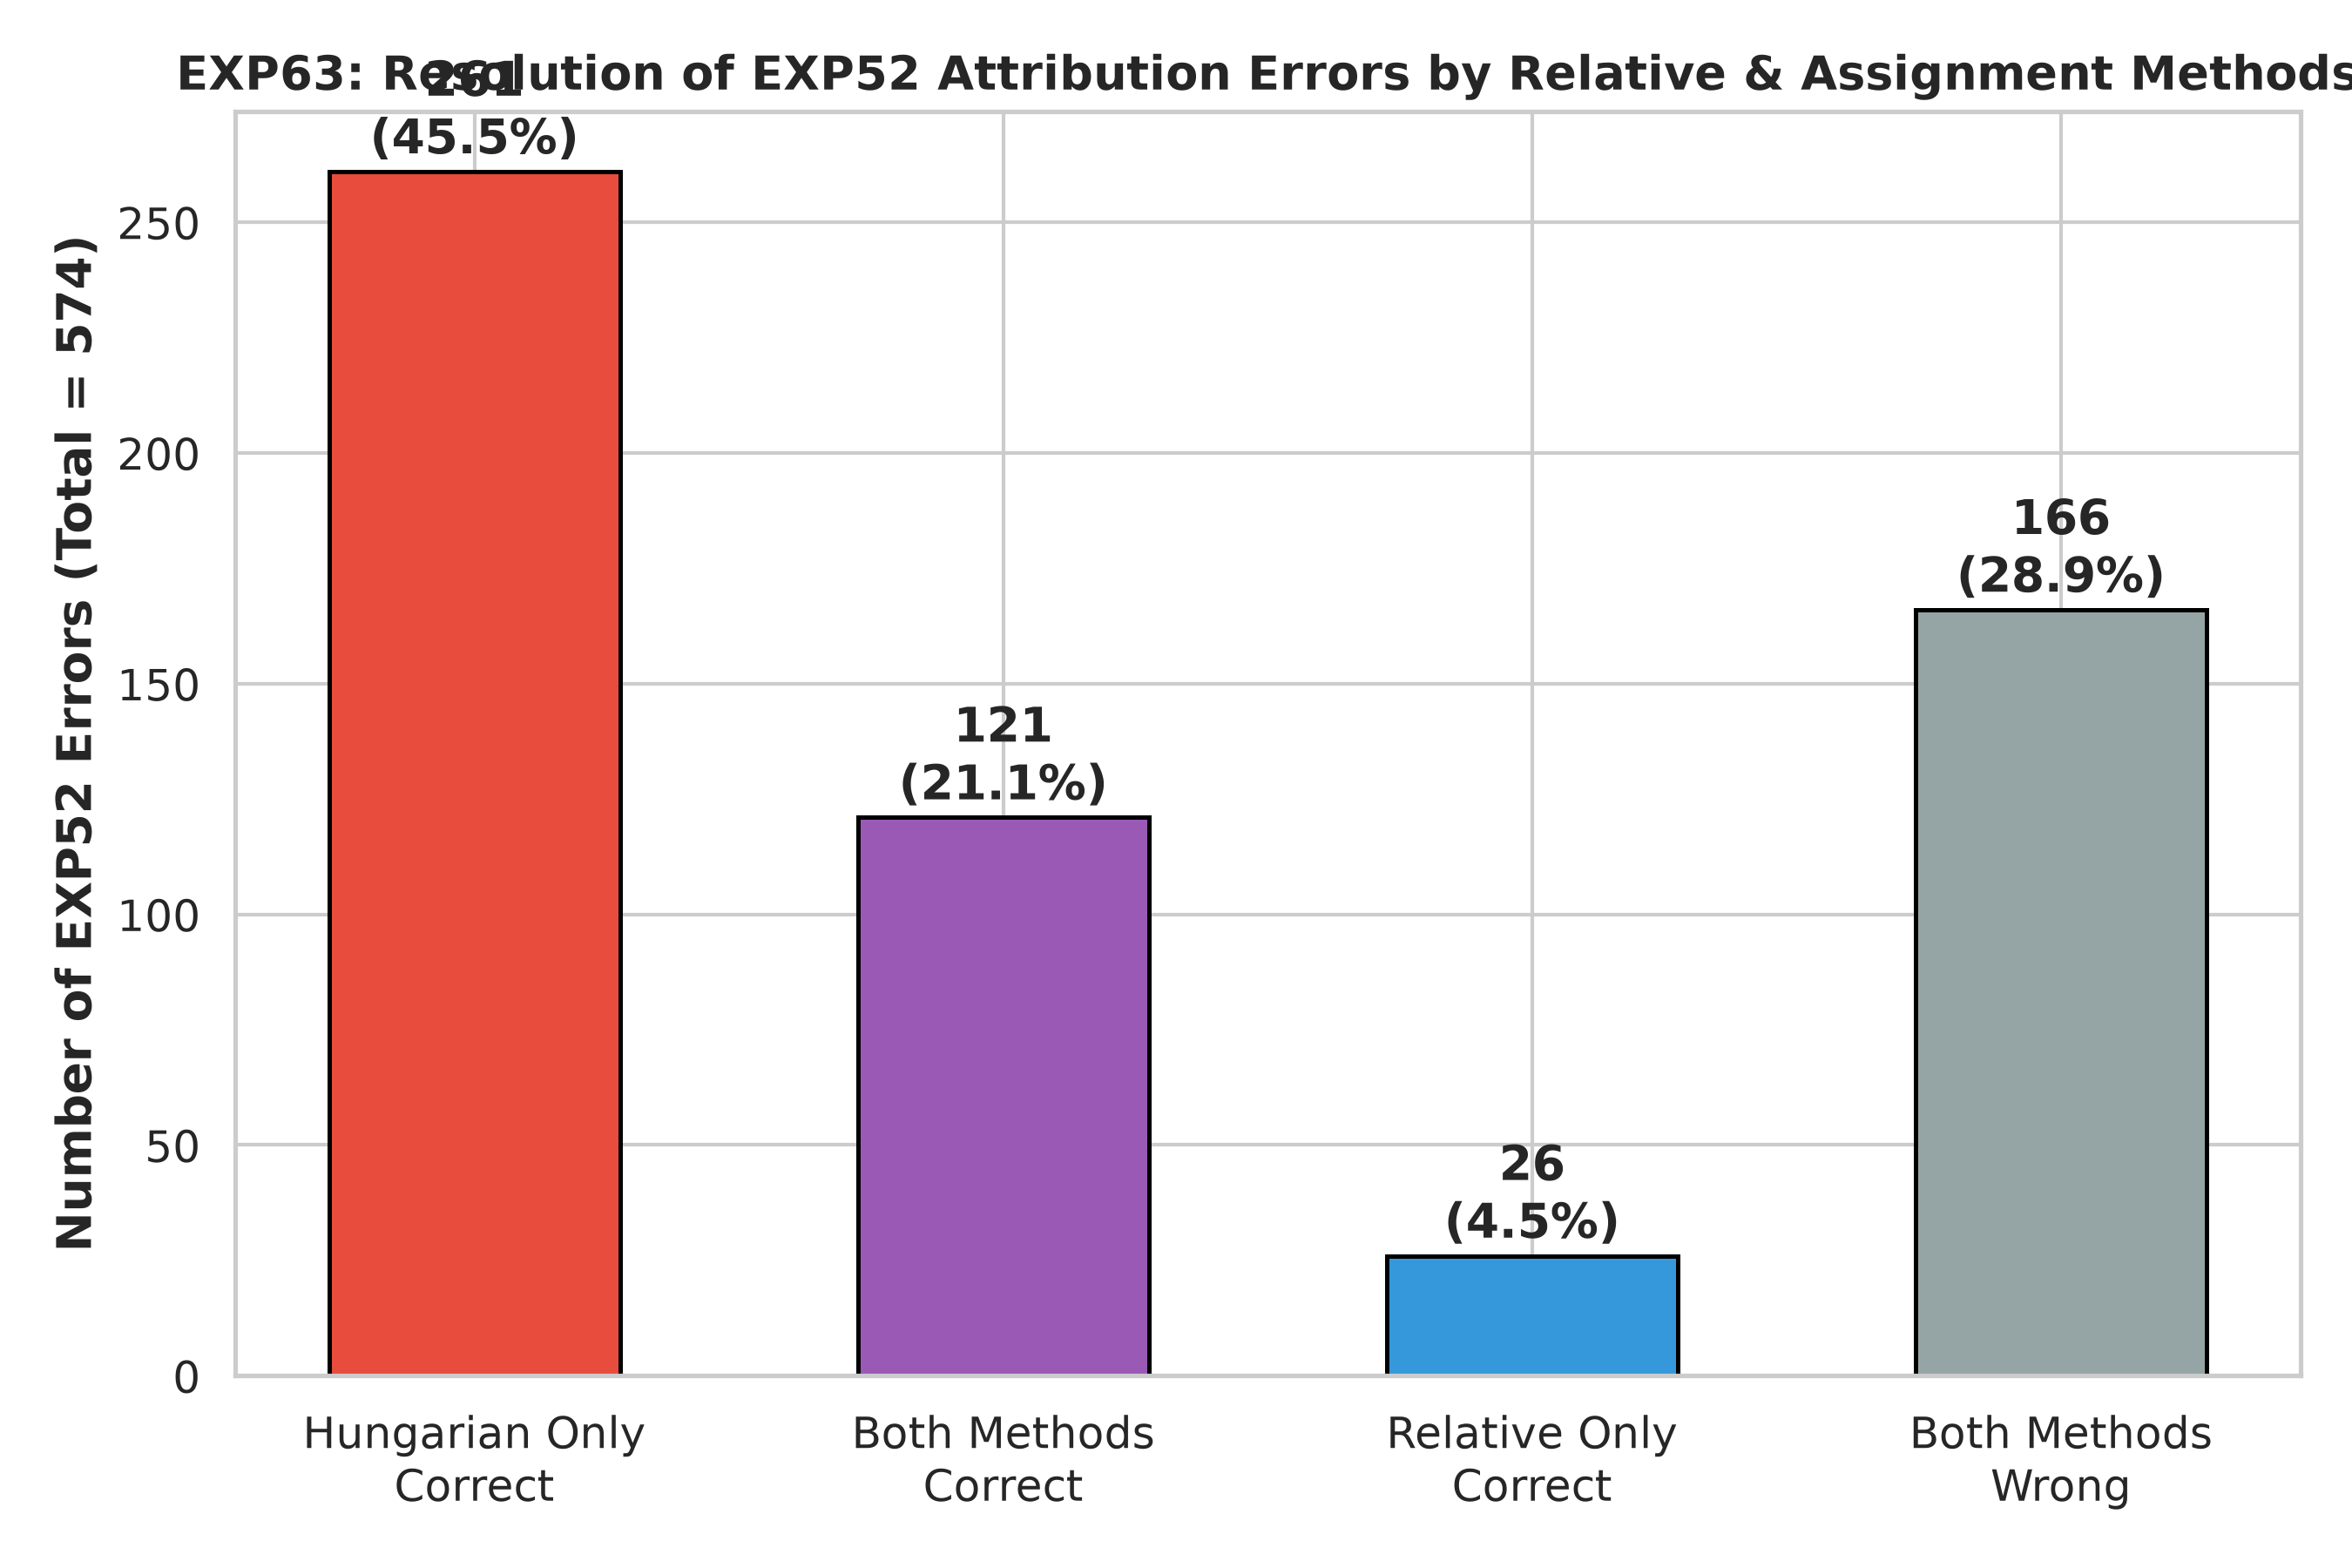

In [7]:
# 7. Complementarity & Figures Display
comp_df = pd.read_csv(EXP_DIR / "complementarity.csv")
display(comp_df)

# Display Key Plots
print("--- Figure 1: Baseline vs Relative Representations ---")
display(Image(filename=str(PLOTS_DIR / "exp63_baseline_vs_relative.png")))

print("--- Figure 2: Assignment Gain Across Dense vs Sparse Regimes ---")
display(Image(filename=str(PLOTS_DIR / "exp63_assignment_gain.png")))

print("--- Figure 3: Error Correction Venn / Category Breakdown ---")
display(Image(filename=str(PLOTS_DIR / "exp63_error_correction.png")))


### 8. Final Verdict & Conclusions

- **Verdict**: **YELLOW**
- **Core Scientific Conclusion**:
  1. Under the dense $R=18$ training construction, Hungarian matching achieves a remarkable **0.9040 BA** ($+0.1167$ gain), fixing $66.55\%$ of EXP52 errors.
  2. However, under realistic sparse test simulation ($R=2$), Hungarian matching delta collapses to **$+0.0052$**, and LOO relative delta drops to **$-0.0085$** (net degradation).
  3. The massive assignment gain is an artifact of the artificial $R=18$ training construction. Because Kaggle test prompts average only $R \approx 2$ responses and do not have prompt identifiers, constrained prompt assignment cannot be safely deployed.
- **Production Decision**: **Retain EXP52 as frozen champion (0.632 LB / 0.7873 OOF BA).**
